# 11 · Watershed and GrabCut segmentation

**Level:** Intermediate  
**Prerequisites:** Notebooks 01–10; binary masks, morphology, and connected components.

## What you will build and learn

- Separate touching objects using distance-transform seeds.
- Understand every watershed marker value.
- Use all four GrabCut mask states correctly.
- Measure segmentation with intersection over union.

## How to use this lesson

Run cells in order with **Shift+Enter**. Predict the result before running each example, then change one parameter and explain what changed. Every default example works offline after setup. Each notebook creates its own data, so previous notebooks do not need to have been run.

Try the exercises before reading the worked solutions. Use **Kernel → Restart Kernel and Run All Cells** to check that your work is reproducible. Keep your own changes in a duplicate notebook if you want to retain the reference version.


## Setup

The cell below imports the libraries and the small display/file helpers. Algorithms are written in the lesson cells. Color arrays passed to `show_images` are assumed to be BGR (OpenCV's usual order); the helper converts them to RGB for Matplotlib. Grayscale arrays are displayed directly. `rng` is a repeatable random generator, so running the notebook again reproduces its sample data.


In [1]:
from pathlib import Path
import sys

# Locate the project whether Jupyter starts in the project or notebooks folder.
start = Path.cwd().resolve()
ROOT = next((p for p in (start, *start.parents) if (p / "course_utils.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Open this notebook from inside the OpenCV Practical project.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import cv2
import numpy as np
import matplotlib.pyplot as plt
from course_utils import show_images, make_scene, load_image, save_image

rng = np.random.default_rng(42)
cv2.setRNGSeed(42)
plt.rcParams.update({"figure.dpi": 100, "font.size": 10})
print(f"OpenCV {cv2.__version__} | NumPy {np.__version__}")


OpenCV 4.14.0 | NumPy 2.5.3


## Step 1 — Create touching objects and inspect the limitation of components
A binary connected-component counter merges objects that touch. Watershed can separate them when we can provide one reliable seed per object. It cannot invent a correct object definition from a binary mask alone.


Connected foreground regions: 2 | intended objects: 3


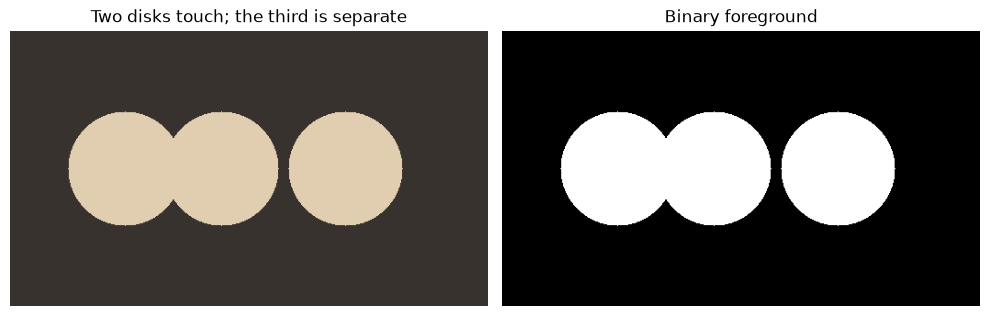

In [2]:
touching = np.zeros((300, 520), np.uint8)
centers = [(125, 150), (230, 150), (365, 150)]
for center in centers:
    cv2.circle(touching, center, 62, 255, -1)
object_image = np.full((300, 520, 3), (45, 50, 55), np.uint8)
object_image[touching > 0] = (175, 205, 225)
component_count, binary_labels = cv2.connectedComponents(touching)
print('Connected foreground regions:', component_count - 1, '| intended objects:', len(centers))
show_images([object_image, touching], ['Two disks touch; the third is separate', 'Binary foreground'], cols=2)


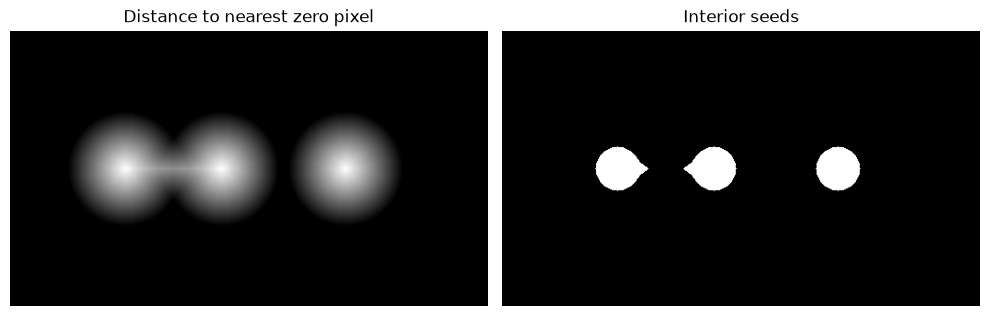

Foreground seed components: 3


In [3]:
distance = cv2.distanceTransform(touching, cv2.DIST_L2, 5)
sure_foreground = np.uint8(distance > .62 * distance.max()) * 255
show_images([distance, sure_foreground], ['Distance to nearest zero pixel', 'Interior seeds'], cols=2)
seed_count, seed_labels = cv2.connectedComponents(sure_foreground)
print('Foreground seed components:', seed_count - 1)
assert seed_count - 1 == 3, 'The selected seed threshold should separate the three centers.'


## Step 2 — Build watershed markers deliberately
Markers must be int32, one channel, and the same height/width as the BGR image. Positive labels identify known regions. Reserve 1 for known background and labels 2+ for object seeds. Set uncertain pixels to 0. After watershed, boundaries are −1. Never pass a 0/255 mask directly and assume it encodes separate objects.


Marker values before: [0 1 2 3 4]


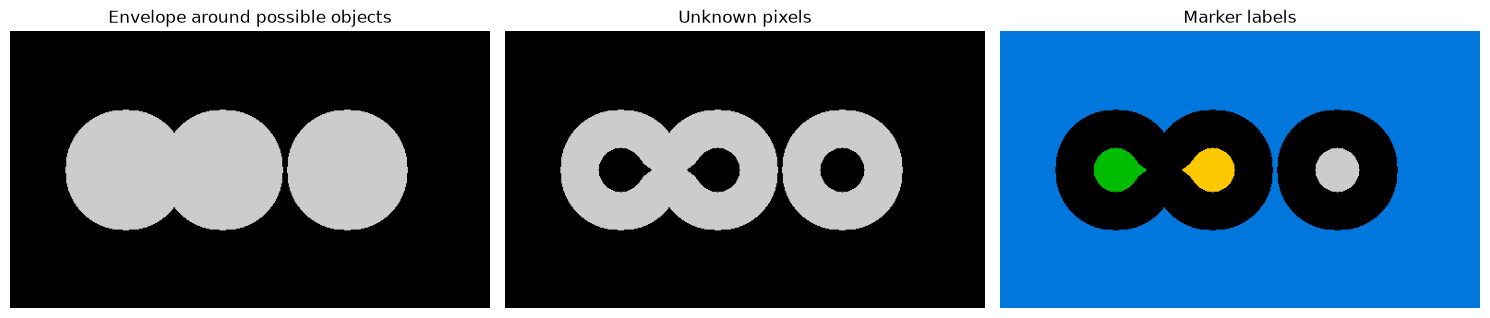

In [4]:
kernel = np.ones((3, 3), np.uint8)
background_envelope = cv2.dilate(touching, kernel, iterations=3)
unknown = cv2.subtract(background_envelope, sure_foreground)
markers = seed_labels.astype(np.int32) + 1
markers[unknown > 0] = 0
before_markers = markers.copy()
print('Marker values before:', np.unique(markers))
assert markers.dtype == np.int32
assert set(np.unique(markers)) == {0, 1, 2, 3, 4}
show_images([background_envelope, unknown, markers], ['Envelope around possible objects', 'Unknown pixels', 'Marker labels'], cmap='nipy_spectral')


Marker values after: [-1  1  2  3  4]
Separated object IDs: [2, 3, 4]


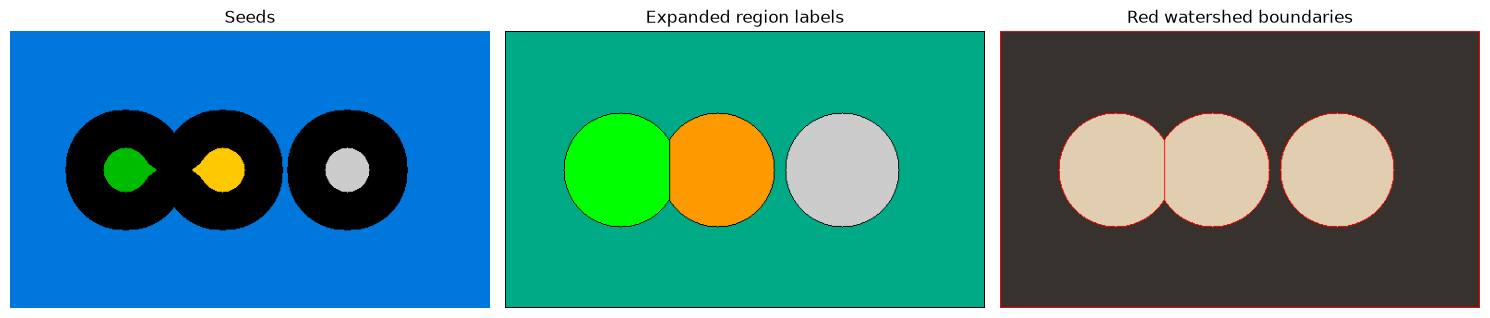

In [5]:
cv2.watershed(object_image.copy(), markers)  # modifies markers in place
watershed_view = object_image.copy()
watershed_view[markers == -1] = (0, 0, 255)
object_labels = [int(label) for label in np.unique(markers) if label > 1]
print('Marker values after:', np.unique(markers))
print('Separated object IDs:', object_labels)
show_images([before_markers, markers, watershed_view], ['Seeds', 'Expanded region labels', 'Red watershed boundaries'], cmap='nipy_spectral')
assert len(object_labels) == 3 and np.any(markers == -1)


In [6]:
for label in object_labels:
    ys, xs = np.where(markers == label)
    print(f'Object {label}: area={len(xs)} pixels, center=({xs.mean():.1f}, {ys.mean():.1f})')
predicted_foreground = markers > 1
ground_truth = touching > 0
intersection = np.count_nonzero(predicted_foreground & ground_truth)
union = np.count_nonzero(predicted_foreground | ground_truth)
print('Combined foreground IoU:', intersection / union)


Object 2: area=11356 pixels, center=(123.2, 150.0)
Object 3: area=11291 pixels, center=(232.1, 150.0)
Object 4: area=11713 pixels, center=(365.0, 150.0)
Combined foreground IoU: 0.9722968957808653


## Step 3 — Experiment with seed thresholds
Too low a distance threshold merges seeds; too high may remove smaller objects. The threshold is relative to the largest distance in this image, which is not scale-aware for objects of very different sizes. Count seeds before trusting the final object count.


fraction=0.25: 2 foreground seeds
fraction=0.62: 3 foreground seeds
fraction=0.9: 3 foreground seeds


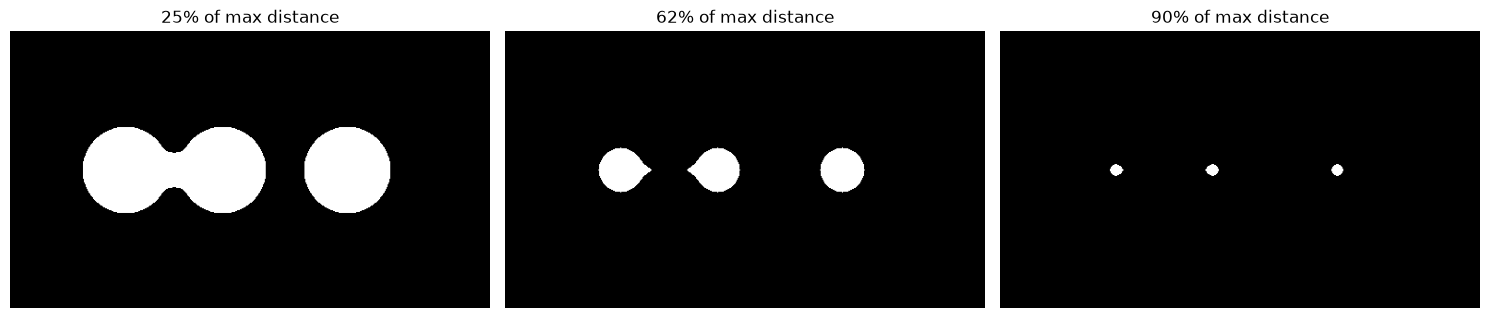

In [7]:
seed_views = []
for fraction in [.25, .62, .9]:
    seed_mask = np.uint8(distance > fraction * distance.max()) * 255
    n, _ = cv2.connectedComponents(seed_mask)
    seed_views.append(seed_mask)
    print(f'fraction={fraction}: {n - 1} foreground seeds')
show_images(seed_views, ['25% of max distance', '62% of max distance', '90% of max distance'])


## Step 4 — Extract a foreground object with GrabCut
GrabCut uses color models plus spatial smoothness, initialized by a rectangle or a mask. It does not understand semantic concepts such as “person.” We create a colored ellipse on a textured background and keep the exact ellipse mask as ground truth.


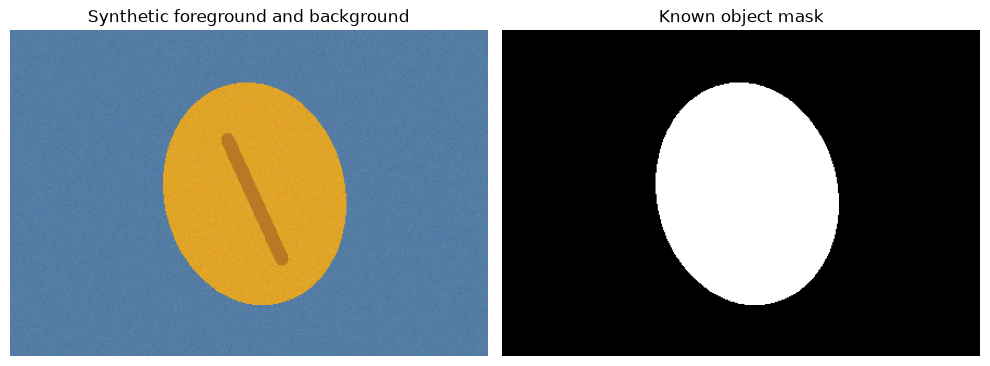

In [8]:
hh, ww = 300, 440
background_noise = rng.normal(0, 5, (hh, ww, 3))
grab_image = np.clip(np.full((hh, ww, 3), (165, 125, 85), np.float32) + background_noise, 0, 255).astype(np.uint8)
true_mask = np.zeros((hh, ww), np.uint8)
cv2.ellipse(true_mask, (225, 150), (83, 103), -12, 0, 360, 255, -1)
object_noise = rng.normal(0, 5, (hh, ww, 3))
object_color = np.clip(np.full((hh, ww, 3), (40, 165, 225), np.float32) + object_noise, 0, 255).astype(np.uint8)
grab_image[true_mask > 0] = object_color[true_mask > 0]
cv2.line(grab_image, (200, 100), (250, 210), (35, 120, 185), 12)
show_images([grab_image, true_mask], ['Synthetic foreground and background', 'Known object mask'], cols=2)


GrabCut masks have four states, **not** ordinary grayscale intensity:

| Constant | Value | Meaning |
|---|---:|---|
| `GC_BGD` | 0 | definite background |
| `GC_FGD` | 1 | definite foreground |
| `GC_PR_BGD` | 2 | probable background |
| `GC_PR_FGD` | 3 | probable foreground |

The final binary foreground includes states 1 **and** 3. The model arrays have shape `(1, 65)` and dtype float64. A rectangle is `(x, y, width, height)`, not two corner coordinates.


Resulting GrabCut states: [0 2 3]


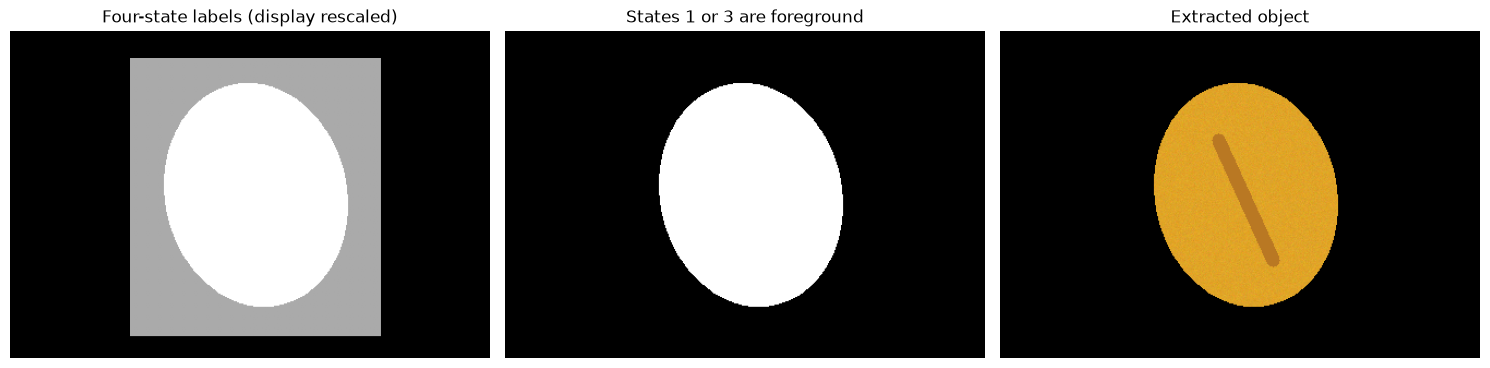

In [9]:
grab_mask = np.zeros((hh, ww), np.uint8)
bg_model = np.zeros((1, 65), np.float64)
fg_model = np.zeros((1, 65), np.float64)
rect = (110, 25, 230, 255)
cv2.setRNGSeed(42)
cv2.grabCut(grab_image, grab_mask, rect, bg_model, fg_model, 5, cv2.GC_INIT_WITH_RECT)
grab_binary = np.isin(grab_mask, [cv2.GC_FGD, cv2.GC_PR_FGD]).astype(np.uint8) * 255
cutout = cv2.bitwise_and(grab_image, grab_image, mask=grab_binary)
print('Resulting GrabCut states:', np.unique(grab_mask))
show_images([grab_mask.astype(np.int32), grab_binary, cutout], ['Four-state labels (display rescaled)', 'States 1 or 3 are foreground', 'Extracted object'])
assert set(np.unique(grab_mask)).issubset({0, 1, 2, 3})


In [10]:
def mask_iou(prediction, truth):
    p, t = np.asarray(prediction) > 0, np.asarray(truth) > 0
    union = np.count_nonzero(p | t)
    return np.count_nonzero(p & t) / union if union else 1.0

print('GrabCut IoU:', mask_iou(grab_binary, true_mask))
assert mask_iou(grab_binary, true_mask) > .9, 'The generated colors should separate cleanly.'
assert mask_iou(np.zeros((3, 3)), np.zeros((3, 3))) == 1.0


GrabCut IoU: 1.0


A rectangle alone can exclude part of the object permanently because outside pixels are definite background. To refine a result, add confident foreground/background strokes to the four-state mask and call `GC_INIT_WITH_MASK`. Keep model arrays when continuing the same image; create fresh arrays for a new image.


Refined IoU: 1.0


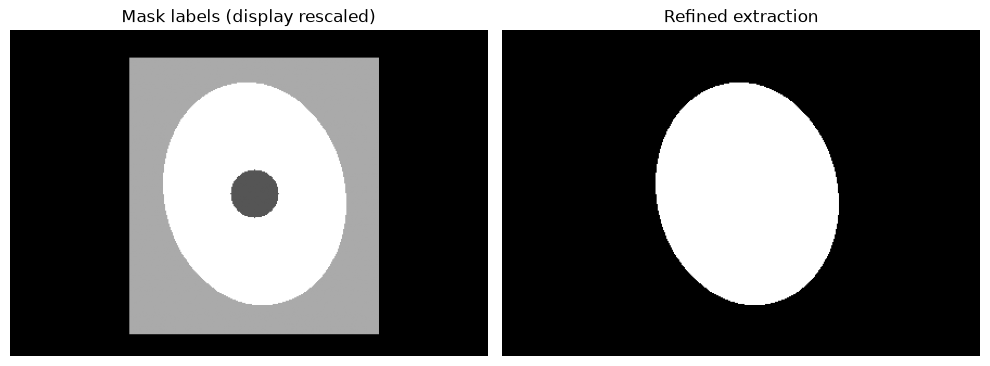

In [11]:
refined_mask = grab_mask.copy()
cv2.circle(refined_mask, (225, 150), 22, cv2.GC_FGD, -1)
cv2.line(refined_mask, (25, 20), (410, 20), cv2.GC_BGD, 8)
cv2.grabCut(grab_image, refined_mask, None, bg_model, fg_model, 3, cv2.GC_INIT_WITH_MASK)
refined_binary = np.isin(refined_mask, [cv2.GC_FGD, cv2.GC_PR_FGD]).astype(np.uint8) * 255
print('Refined IoU:', mask_iou(refined_binary, true_mask))
show_images([refined_mask.astype(np.int32), refined_binary], ['Mask labels (display rescaled)', 'Refined extraction'], cols=2)


## Step 5 — Mini-project: export a foreground cutout with transparency
Use the binary mask as the alpha channel. OpenCV stores this array as BGRA, so convert it to RGBA when displaying with Matplotlib directly. Our normal image helper is intended primarily for BGR/gray images.


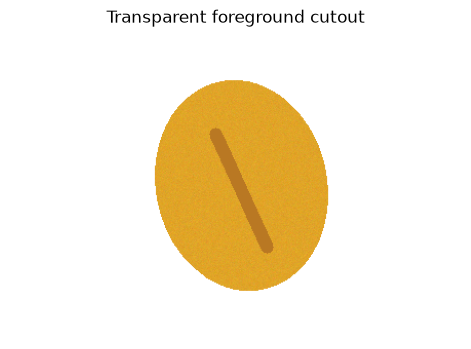

Saved: C:\Users\Hareram ray\AI\OpencvPractical\outputs\11_segmentation


In [12]:
bgra = cv2.cvtColor(grab_image, cv2.COLOR_BGR2BGRA)
bgra[:, :, 3] = refined_binary
out_dir = ROOT / 'outputs' / '11_segmentation'
out_dir.mkdir(parents=True, exist_ok=True)
save_image(out_dir / 'foreground_cutout.png', bgra)
save_image(out_dir / 'watershed_boundaries.png', watershed_view)
plt.figure(figsize=(7, 4))
plt.imshow(cv2.cvtColor(bgra, cv2.COLOR_BGRA2RGBA)); plt.axis('off'); plt.title('Transparent foreground cutout'); plt.show()
assert np.array_equal(bgra[:, :, 3], refined_binary)
print('Saved:', out_dir)


### Pitfalls and practice
- Watershed modifies markers and labels the outer image border as boundary too. A red border is expected.
- The dilated mask often called `sure_bg` is an envelope: pixels *outside* it are known background.
- GrabCut label 2 is probable background, not 50% transparency.
- IoU evaluates pixel overlap, not whether touching instances were separated correctly.

1. Count the pixels in each GrabCut state.
2. Show the disagreement mask between the GrabCut result and the known foreground.
3. Use a too-tight initialization rectangle and measure the resulting IoU. Explain the lost foreground.


## Worked solutions
Run a fresh model for the rectangle comparison so previous model state does not confound the experiment.


definite background : 73350
definite foreground : 1517
probable background : 31553
probable foreground : 25580


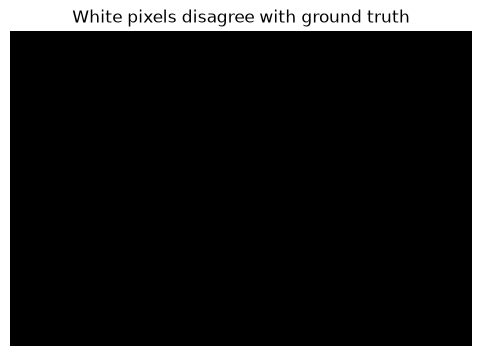

In [13]:
state_names = {0: 'definite background', 1: 'definite foreground',
               2: 'probable background', 3: 'probable foreground'}
for state, name in state_names.items():
    print(name, ':', np.count_nonzero(refined_mask == state))
disagreement = np.uint8((refined_binary > 0) != (true_mask > 0)) * 255
show_images([disagreement], ['White pixels disagree with ground truth'])


Too-tight rectangle IoU: 0.05989592943868325


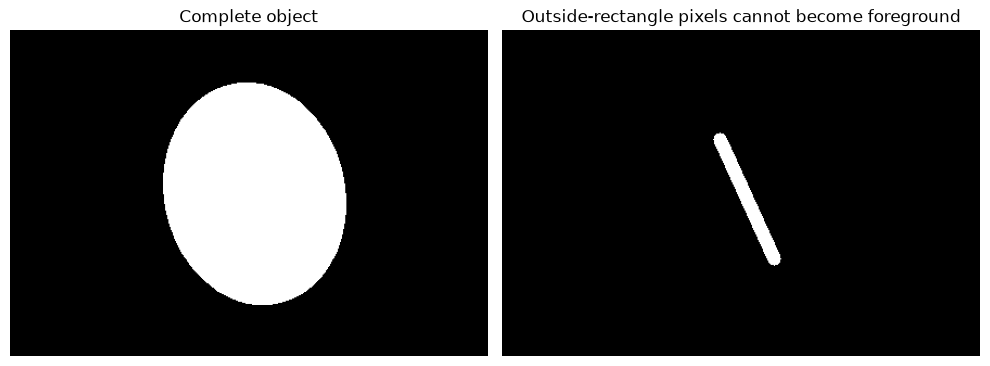

In [14]:
tight_mask = np.zeros((hh, ww), np.uint8)
tight_bg, tight_fg = np.zeros((1, 65), np.float64), np.zeros((1, 65), np.float64)
cv2.grabCut(grab_image, tight_mask, (175, 75, 105, 150), tight_bg, tight_fg, 4, cv2.GC_INIT_WITH_RECT)
tight_binary = np.isin(tight_mask, [cv2.GC_FGD, cv2.GC_PR_FGD]).astype(np.uint8) * 255
print('Too-tight rectangle IoU:', mask_iou(tight_binary, true_mask))
show_images([true_mask, tight_binary], ['Complete object', 'Outside-rectangle pixels cannot become foreground'], cols=2)


### Reflection
When would you choose watershed, and when would you choose GrabCut? What seed or annotation error would be most damaging in each method?

Official references: [Watershed tutorial](https://docs.opencv.org/4.x/d3/db4/tutorial_py_watershed.html), [GrabCut tutorial](https://docs.opencv.org/4.x/d8/d83/tutorial_py_grabcut.html), [Segmentation API](https://docs.opencv.org/4.x/d3/d47/group__imgproc__segmentation.html).
